In [9]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
pd.set_option("display.max_columns", 50); pd.set_option("display.width", 200)

num_cols = ["age","Medu","Fedu","traveltime","studytime","failures","famrel","freetime","goout",
            "Dalc","Walc","health","absences","G1","G2","G3","Tinggi","Berat","Bulan"]
cat_cols = ["school","sex","address","famsize","Mjob","Fjob","reason","guardian","higher","internet",
            "romantic","Status_Kesehatan","Test_Result"]
PLACEHOLDER = ["?","-","n/a","unknown","it"]
RULES = {"age":(15,22),"Medu":(0,4),"Fedu":(0,4),"traveltime":(1,4),"studytime":(1,4),"famrel":(1,5),
         "freetime":(1,5),"goout":(1,5),"Dalc":(1,5),"Walc":(1,5),"health":(1,5),
         "G1":(0,20),"G2":(0,20),"G3":(0,20),"Tinggi":(1.4,2.1),"Berat":(30,150),"absences":(0,93)}

def to_num(s):
    # ambil angka dari teks, mis. '17 tahun' -> 17, '60.5 kg' -> 60.5, '?' -> NaN
    return pd.to_numeric(s.astype(str).str.extract(r"(-?\d+\.?\d*)")[0], errors="coerce")

---
## TAHAP 1 – Deteksi Masalah Data
**INPUT:** `dataset_student_kotor.csv`
**PROSES:** profil data, cek nilai unik kategorik, cek tipe data, missing value tersamar, pelanggaran aturan validasi, duplikat, inkonsistensi antar variabel.
**OUTPUT:** tabel temuan masalah (kolom, jenis masalah, jumlah baris, bukti).

In [11]:
df_raw = pd.read_csv("/content/drive/MyDrive/dataset_student_kotor.csv")
print("Dimensi:", df_raw.shape)
df_raw.head()

Dimensi: (412, 33)


,ID_Siswa,school,sex,age,address,famsize,Mjob,Fjob,reason,guardian,higher,internet,romantic,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3,Tinggi,Berat,Bulan,Status_Kesehatan,Test_Result
0,S241,GP,M,17,U,LE3,health,other,course,mother,yes,yes,yes,4.0,3,2,2.0,0,2.0,5,5,NaN,4,5.0,14.0,12.0,12.0,12.0,1.84,66.4,6,High,Pass
1,S249,GP,M,18,R,LE3,other,services,NaN,mother,yes,yes,yes,NaN,3,1,2.0,1,4.0,3,3,NaN,3,5.0,8.0,3.0,5.0,5.0,1.78,56.8,11,High,Fail
2,S061,GP,F,16,R,GT3,NaN,teacher,other,mother,yes,no,no,4.0,4,1,2.0,0,2.0,4,4,2.0,3,4.0,6.0,10.0,11.0,11.0,1.53,450.0,7,High,Pass
3,S031,GP,M,15,U,GT3,unknown,services,home,mother,yes,yes,no,4.0,4,1,2.0,0,5.0,4,2,3.0,4,5.0,0.0,9.0,11.0,12.0,1.72,71.2,5,High,Pass
4,S388,MS,F,19,NaN,GT3,services,other,course,mother,yes,yes,no,2.0,3,1,3.0,1,5.0,4,2,1.0,2,5.0,0.0,7.0,5.0,0.0,1.59,64.4,4,High,Fail


In [12]:
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 412 entries, 0 to 411
Data columns (total 33 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   ID_Siswa          412 non-null    object 
 1   school            412 non-null    object 
 2   sex               401 non-null    object 
 3   age               393 non-null    object 
 4   address           393 non-null    object 
 5   famsize           412 non-null    object 
 6   Mjob              391 non-null    object 
 7   Fjob              397 non-null    object 
 8   reason            390 non-null    object 
 9   guardian          397 non-null    object 
 10  higher            397 non-null    object 
 11  internet          384 non-null    object 
 12  romantic          380 non-null    object 
 13  Medu              396 non-null    float64
 14  Fedu              412 non-null    object 
 15  traveltime        412 non-null    int64  
 16  studytime         393 non-null    float64
 1

In [13]:
df_raw.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
ID_Siswa,412,395,S370,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
school,412,4,GP,326,NaN,NaN,NaN,NaN,NaN,NaN,NaN
sex,401,6,F,192,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,393,17,16,99,NaN,NaN,NaN,NaN,NaN,NaN,NaN
address,393,2,U,304,NaN,NaN,NaN,NaN,NaN,NaN,NaN
famsize,412,3,GT3,290,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Mjob,391,17,other,109,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Fjob,397,9,other,198,NaN,NaN,NaN,NaN,NaN,NaN,NaN
reason,390,8,course,138,NaN,NaN,NaN,NaN,NaN,NaN,NaN
guardian,397,4,mother,266,NaN,NaN,NaN,NaN,NaN,NaN,NaN


**1a. Nilai unik tiap kolom kategorik** (mendeteksi huruf besar/kecil, spasi, typo, singkatan)


In [14]:
for c in cat_cols:
    print(f"{c:18s}", sorted(df_raw[c].dropna().unique().tolist(), key=str))

school             ['GP', 'MS', 'gp', 'ms']
sex                ['F', 'M', 'MALE', 'Male', 'f', 'female']
address            ['R', 'U']
famsize            ['?', 'GT3', 'LE3']
Mjob               ['  OTHER ', '  TEACHER ', '  at_home ', '  health ', '  other ', '  services ', '  teacher ', 'AT_HOME', 'OTHER', 'SERVICES', 'TEACHER', 'at_home', 'health', 'other', 'services', 'teacher', 'unknown']
Fjob               ['Other', 'Services', 'Teacher', 'at  home', 'at_home', 'health', 'other', 'services', 'teacher']
reason             [' course', ' home', ' other', ' reputation', 'course', 'home', 'other', 'reputation']
guardian           ['father', 'it', 'mother', 'other']
higher             ['no', 'yes']
internet           ['no', 'yes']
romantic           ['no', 'yes']
Status_Kesehatan   ['High', 'High  ', 'Low', 'Low  ', 'Medium', 'Medium  ']
Test_Result        ['Fail', 'Failed', 'Pas', 'Pass', 'fail', 'failed', 'pas', 'pass']


**1b. Kolom numerik yang terbaca sebagai teks** (tipe data/format salah, mis. `17 tahun`, `60 kg`, `?`)


In [15]:
rows = []
for c in num_cols:
    conv = pd.to_numeric(df_raw[c], errors="coerce")
    bad = df_raw[c].notna() & conv.isna()
    rows.append((c, str(df_raw[c].dtype), int(bad.sum()), df_raw.loc[bad, c].unique()[:6].tolist()))
tipe_salah = pd.DataFrame(rows, columns=["kolom","dtype","jumlah_non_angka","contoh_nilai"])
tipe_salah[tipe_salah.jumlah_non_angka > 0]

,kolom,dtype,jumlah_non_angka,contoh_nilai
0,age,object,10,"[16 tahun, 17 tahun, 15 tahun, 18 tahun, 19 tahun]"
2,Fedu,object,8,[?]
8,goout,object,6,[-]
17,Berat,object,8,"[47.2 kg, 74.9 kg, 64.3 kg, 71.9 kg, 47.7 kg, 69.5 kg]"


**1c. Missing value tersamar** (nilai pengganti data kosong: `?`, `-`, `N/A`, `unknown`, `it`, atau 0 pada Berat/Tinggi)


In [16]:
txt = df_raw.select_dtypes(include="object")
ph = txt.apply(lambda s: s.astype(str).str.strip().str.lower().isin(PLACEHOLDER)).sum()
print("Placeholder teks per kolom:"); print(ph[ph > 0])
print("\nNilai 0 pada Berat :", (to_num(df_raw.Berat) == 0).sum())
print("Nilai 0 pada Tinggi:", (to_num(df_raw.Tinggi) == 0).sum())
print("\nMissing value asli (NaN) per kolom:"); print(df_raw.isna().sum()[df_raw.isna().sum() > 0])

Placeholder teks per kolom:
famsize     6
Mjob        8
guardian    7
Fedu        8
goout       6
dtype: int64

Nilai 0 pada Berat : 9
Nilai 0 pada Tinggi: 5

Missing value asli (NaN) per kolom:
sex          11
age          19
address      19
Mjob         21
Fjob         15
reason       22
guardian     15
higher       15
internet     28
romantic     32
Medu         16
studytime    19
famrel        8
Dalc         15
health       21
absences     24
G1           16
G2           20
G3           11
Tinggi       24
Berat        45
dtype: int64


**1d. Pelanggaran aturan validasi sekolah & outlier**


In [18]:
rows = []
for c, (lo, hi) in RULES.items():
    v = to_num(df_raw[c])
    if c == "Tinggi": v = v.where(~v.between(100, 250), v / 100)   # cm -> m dulu
    rows.append((c, f"{lo}-{hi}", int(((v < lo) | (v > hi)).sum()), v[(v < lo) | (v > hi)].unique()[:8].tolist()))
pd.DataFrame(rows, columns=["kolom","rentang_valid","jumlah_pelanggaran","contoh_nilai"]).query("jumlah_pelanggaran > 0")

,kolom,rentang_valid,jumlah_pelanggaran,contoh_nilai
0,age,15-22,4,"[0.0, 130.0, 150.0, -5.0]"
13,G3,0-20,2,"[35.0, -4.0]"
14,Tinggi,1.4-2.1,6,"[0.0, 3.9]"
15,Berat,30-150,10,"[450.0, 0.0]"
16,absences,0-93,2,"[-8.0, 400.0]"


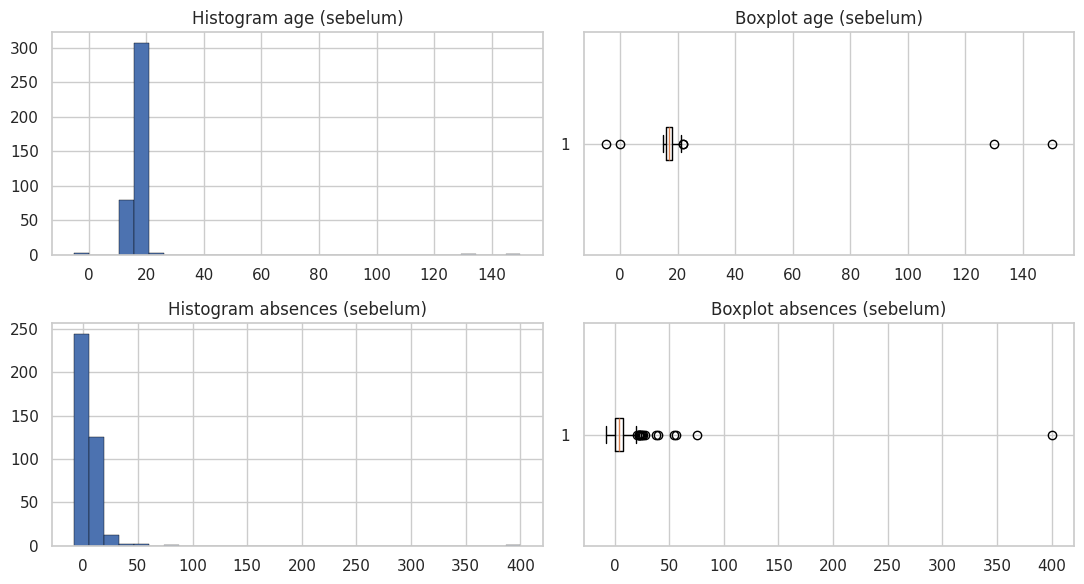

In [19]:
fig, ax = plt.subplots(2, 2, figsize=(11, 6))
for i, c in enumerate(["age", "absences"]):
    v = to_num(df_raw[c]).dropna()
    ax[i,0].hist(v, bins=30, edgecolor="black", linewidth=.3); ax[i,0].set_title(f"Histogram {c} (sebelum)")
    ax[i,1].boxplot(v, vert=False); ax[i,1].set_title(f"Boxplot {c} (sebelum)")
plt.tight_layout(); plt.show()

**1e. Satuan tidak seragam (Tinggi), duplikat, dan inkonsistensi Test_Result vs G3**

In [20]:
t = to_num(df_raw.Tinggi)
print("Tinggi dalam meter (1.0-2.5):", t.between(1.0, 2.5).sum(), "| dalam cm (100-250):", t.between(100, 250).sum())
print("\nDuplikat persis      :", df_raw.duplicated().sum())
print("ID_Siswa terduplikasi (termasuk near-duplicate):", df_raw.duplicated(subset="ID_Siswa").sum())
g3 = to_num(df_raw.G3)
valid = g3.between(0, 20)
exp = np.where(g3 >= 10, "pass", "fail")
tr = df_raw.Test_Result.astype(str).str.strip().str.lower().replace({"failed":"fail","pas":"pass"})
print("Test_Result tidak sesuai G3 (aturan G3>=10):", int((valid & (tr != exp)).sum()))

Tinggi dalam meter (1.0-2.5): 368 | dalam cm (100-250): 14

Duplikat persis      : 12
ID_Siswa terduplikasi (termasuk near-duplicate): 17
Test_Result tidak sesuai G3 (aturan G3>=10): 14


---
## TAHAP 2 – Pembersihan Data
**INPUT:** `df_raw` + daftar masalah Tahap 1
**PROSES:** hapus spasi, seragamkan label & huruf, ubah placeholder → NaN, perbaiki tipe data, seragamkan satuan, nilai melanggar aturan → NaN, hapus duplikat, perbaiki inkonsistensi.
**OUTPUT:** `df` bersih dari masalah format (missing value masih ada, ditangani di Tahap 3).

In [21]:
df = df_raw.copy()
log = {}

# 2a. spasi berlebih (depan, belakang, ganda di tengah)
tc = df.select_dtypes(include="object").columns
df[tc] = df[tc].apply(lambda s: s.str.strip().str.replace(r"\s+", " ", regex=True))

# 2b. placeholder teks -> NaN
mask = df[tc].apply(lambda s: s.str.lower().isin(PLACEHOLDER))
log["placeholder teks -> NaN"] = int(mask.sum().sum())
df[tc] = df[tc].mask(mask)

# 2c. seragamkan kategori
df["school"] = df.school.str.upper()
df["sex"] = df.sex.str.lower().map({"f":"F","female":"F","m":"M","male":"M"})
for c in ["Mjob","Fjob"]:
    df[c] = df[c].str.lower().str.replace(" ", "_")
df["reason"] = df.reason.str.lower()
df["Status_Kesehatan"] = df.Status_Kesehatan.str.capitalize()
df["Test_Result"] = df.Test_Result.str.lower().replace({"failed":"Fail","fail":"Fail","pas":"Pass","pass":"Pass"})
for c in ["school","sex","Mjob","Fjob","reason","Status_Kesehatan","Test_Result"]:
    print(f"{c:18s}", sorted(df[c].dropna().unique()))

school             ['GP', 'MS']
sex                ['F', 'M']
Mjob               ['at_home', 'health', 'other', 'services', 'teacher']
Fjob               ['at_home', 'health', 'other', 'services', 'teacher']
reason             ['course', 'home', 'other', 'reputation']
Status_Kesehatan   ['High', 'Low', 'Medium']
Test_Result        ['Fail', 'Pass']


In [22]:
# 2d. perbaiki tipe data (ambil angka dari teks)
for c in num_cols:
    df[c] = to_num(df[c])

# 2e. seragamkan satuan Tinggi: cm -> meter (x/100); nol = placeholder -> NaN
cm = df.Tinggi.between(100, 250)
log["Tinggi cm -> m"] = int(cm.sum())
df.loc[cm, "Tinggi"] = df.loc[cm, "Tinggi"] / 100
for c in ["Berat", "Tinggi"]:
    z = df[c] == 0
    log[f"{c}=0 -> NaN"] = int(z.sum()); df.loc[z, c] = np.nan

# 2f. nilai melanggar aturan validasi -> NaN
for c, (lo, hi) in RULES.items():
    bad = (df[c] < lo) | (df[c] > hi)
    log[f"{c} di luar {lo}-{hi} -> NaN"] = int(bad.sum()); df.loc[bad, c] = np.nan
pd.Series(log)[lambda s: s > 0]

,0
placeholder teks -> NaN,35
Tinggi cm -> m,14
Berat=0 -> NaN,9
Tinggi=0 -> NaN,5
age di luar 15-22 -> NaN,4
G3 di luar 0-20 -> NaN,2
Tinggi di luar 1.4-2.1 -> NaN,1
Berat di luar 30-150 -> NaN,1
absences di luar 0-93 -> NaN,2


In [23]:
# 2g. duplikat: persis, lalu near-duplicate (ID sama)
n0 = len(df)
df = df.drop_duplicates()
n1 = len(df)
df = df.drop_duplicates(subset="ID_Siswa", keep="first")
print(f"Baris awal {n0} -> hapus duplikat persis {n0-n1} -> hapus near-duplicate {n1-len(df)} -> sisa {len(df)}")

# 2h. konsistensi Test_Result vs G3 (aturan: Pass jika G3 >= 10)
expected = pd.Series(np.where(df.G3 >= 10, "Pass", "Fail"), index=df.index)
mism = df.G3.notna() & (df.Test_Result != expected)
print("Test_Result dikoreksi:", int(mism.sum()))
df.loc[mism, "Test_Result"] = expected[mism]
df = df.reset_index(drop=True)
df.isna().sum()[df.isna().sum() > 0]

Baris awal 412 -> hapus duplikat persis 12 -> hapus near-duplicate 5 -> sisa 395
Test_Result dikoreksi: 12


,0
sex,11
age,23
address,19
famsize,6
Mjob,27
Fjob,15
reason,19
guardian,21
higher,15
internet,27


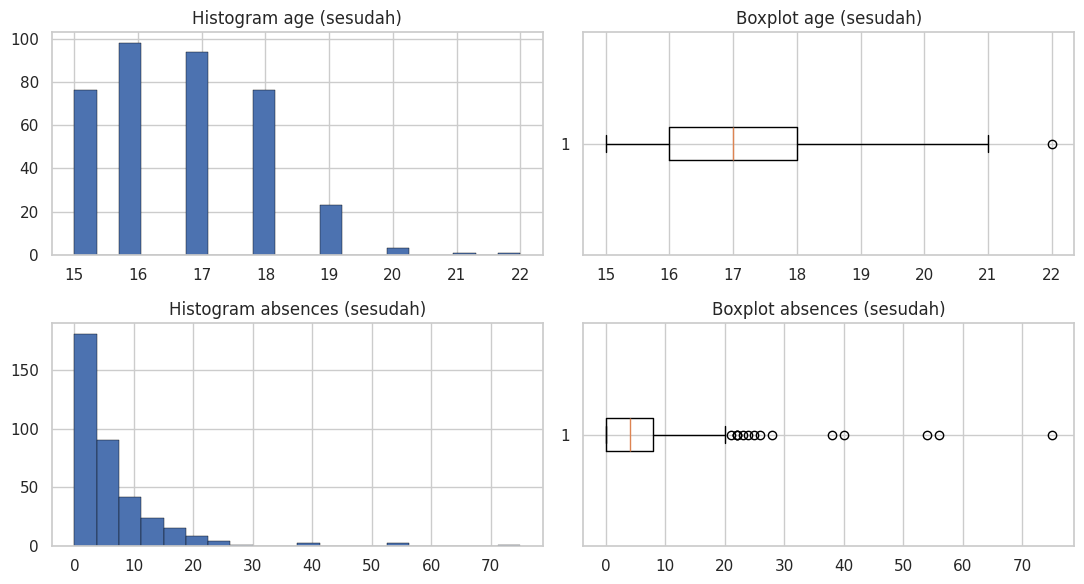

In [24]:
fig, ax = plt.subplots(2, 2, figsize=(11, 6))
for i, c in enumerate(["age", "absences"]):
    v = df[c].dropna()
    ax[i,0].hist(v, bins=20, edgecolor="black", linewidth=.3); ax[i,0].set_title(f"Histogram {c} (sesudah)")
    ax[i,1].boxplot(v, vert=False); ax[i,1].set_title(f"Boxplot {c} (sesudah)")
plt.tight_layout(); plt.show()

**Penjelasan singkat:** nilai yang melanggar aturan (mis. usia -5 atau 150, G3 35, berat 450 kg) tidak mungkin benar sehingga diubah menjadi NaN, lalu diisi pada Tahap 3 (bukan dibuang, agar baris lain tidak hilang). Duplikat persis dihapus; untuk near-duplicate (ID sama, `absences` beda 1) dipertahankan baris pertama.


---
## TAHAP 3 – Penanganan Missing Value
**INPUT:** `df` hasil Tahap 2
**PROSES:** hitung & visualisasi missing, statistik deskriptif (mean, median, skewness), bandingkan strategi, tentukan strategi final per kolom.
**OUTPUT:** `dfc` tanpa missing value.

In [25]:
mv = df.isna().sum()
mv_tbl = pd.DataFrame({"jumlah": mv, "persen": (mv / len(df) * 100).round(2)})
mv_tbl[mv_tbl.jumlah > 0].sort_values("jumlah", ascending=False)

,jumlah,persen
Berat,51,12.91
romantic,31,7.85
Tinggi,29,7.34
Mjob,27,6.84
internet,27,6.84
absences,25,6.33
age,23,5.82
guardian,21,5.32
address,19,4.81
health,19,4.81


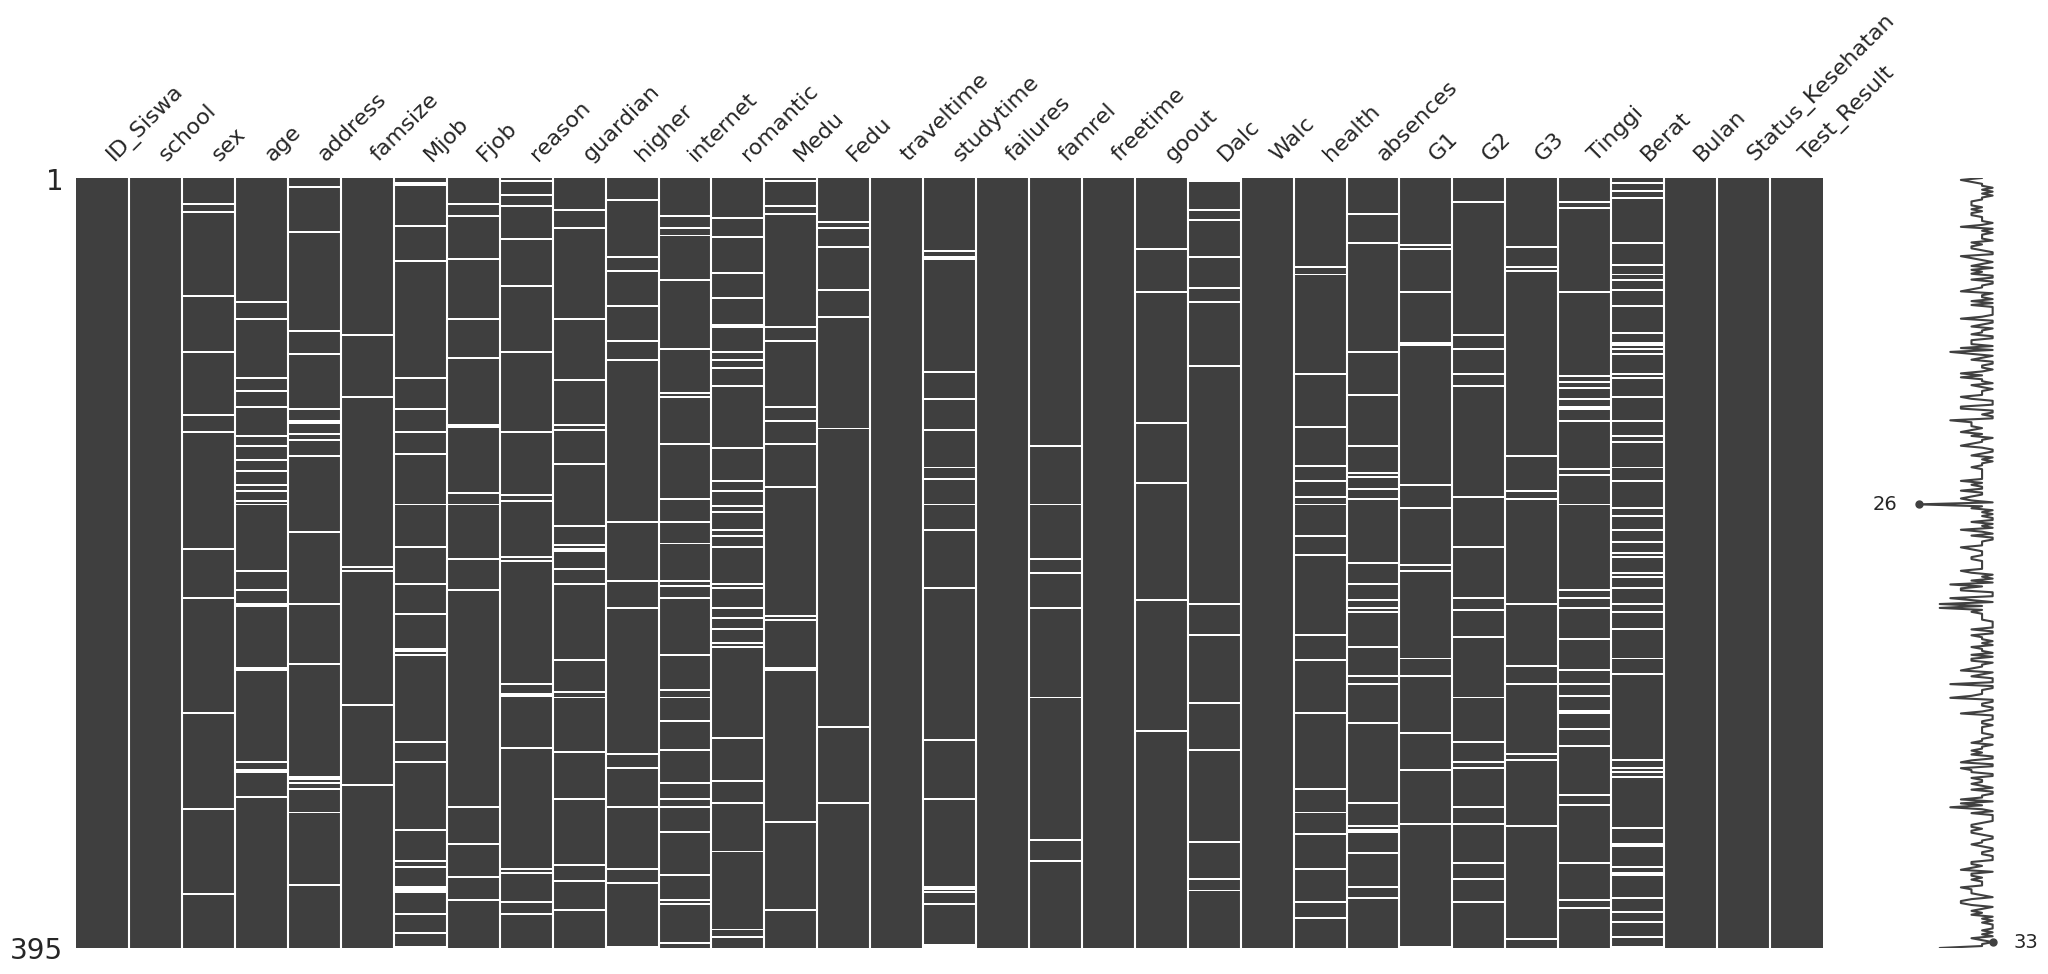

In [26]:
try:
    import missingno as msno
    msno.matrix(df); plt.show()
except Exception as e:
    plt.figure(figsize=(12, 4)); sns.heatmap(df.isna(), cbar=False); plt.title("Pola missing value"); plt.show()

**3a. Apakah missing acak atau berpola?** (contoh: Berat per jenis kelamin)


In [27]:
pola = df.assign(Berat_kosong=df.Berat.isna(), Tinggi_kosong=df.Tinggi.isna()).groupby("sex", dropna=False)[["Berat_kosong","Tinggi_kosong"]].mean().round(3)
print("Proporsi missing per jenis kelamin:"); print(pola)

Proporsi missing per jenis kelamin:
     Berat_kosong  Tinggi_kosong
sex                             
F           0.183          0.071
M           0.080          0.070
NaN         0.000          0.182


**3c. Perbandingan strategi pada kolom `Berat`** (hapus baris, hapus kolom, isi 0, isi mean, isi median)


In [28]:
asli = df.Berat.dropna()
hasil = {
 "Data asli (tanpa NaN)": (len(asli), asli.mean(), asli.median(), asli.std()),
 "Hapus baris (dropna)":  (len(df.dropna()), df.dropna().Berat.mean(), df.dropna().Berat.median(), df.dropna().Berat.std()),
 "Isi 0":     (len(df), df.Berat.fillna(0).mean(), df.Berat.fillna(0).median(), df.Berat.fillna(0).std()),
 "Isi mean":  (len(df), df.Berat.fillna(df.Berat.mean()).mean(), df.Berat.fillna(df.Berat.mean()).median(), df.Berat.fillna(df.Berat.mean()).std()),
 "Isi median":(len(df), df.Berat.fillna(df.Berat.median()).mean(), df.Berat.fillna(df.Berat.median()).median(), df.Berat.fillna(df.Berat.median()).std()),
}
print("Hapus kolom (dropna axis=1) menyisakan", df.dropna(axis=1).shape[1], "dari", df.shape[1], "kolom -> terlalu banyak informasi hilang")
pd.DataFrame(hasil, index=["jumlah_baris","mean","median","std"]).T.round(3)

Hapus kolom (dropna axis=1) menyisakan 9 dari 33 kolom -> terlalu banyak informasi hilang


,jumlah_baris,mean,median,std
Data asli (tanpa NaN),344.0,60.082,59.350,10.624
Hapus baris (dropna),126.0,59.290,58.600,9.250
Isi 0,395.0,52.325,57.300,22.477
Isi mean,395.0,60.082,60.082,9.913
Isi median,395.0,59.988,59.350,9.916


**Kesimpulan 3c:** hapus baris membuang sebagian besar data (hanya sekitar sepertiga baris yang lengkap); hapus kolom hanya menyisakan 9 dari 33 variabel; isi 0 merusak rata-rata dan sebaran. Imputasi mean/median menjaga jumlah data dan sebaran tetap wajar dipilih untuk kolom numerik, modus untuk kategorik.


**3d. [TANTANGAN] Imputasi `Berat` & `Tinggi` per kelompok jenis kelamin**


In [29]:
dfc = df.copy()
base = pd.DataFrame({"Berat_mean_global": dfc.Berat.fillna(dfc.Berat.mean()),
                     "Tinggi_mean_global": dfc.Tinggi.fillna(dfc.Tinggi.mean()), "sex": dfc.sex})
for c in ["Berat", "Tinggi"]:
    grp = dfc.groupby("sex")[c].transform("mean")
    dfc[c] = dfc[c].fillna(grp).fillna(dfc[c].mean())       # cadangan jika sex juga NaN
banding = pd.concat([base.groupby("sex").mean(), dfc.groupby("sex")[["Berat","Tinggi"]].mean().add_suffix("_per_kelompok")], axis=1).round(3)
print("Rata-rata per jenis kelamin: global vs per-kelompok"); banding

Rata-rata per jenis kelamin: global vs per-kelompok


,Berat_mean_global,Tinggi_mean_global,Berat_per_kelompok,Tinggi_per_kelompok
sex,,,,
F,57.074,1.622,56.401,1.618
M,62.984,1.726,63.237,1.730


**penjelasan:** laki-laki dan perempuan punya tinggi/berat rata-rata berbeda, dan missing `Berat` lebih sering pada siswa perempuan. Mengisi dengan rata-rata global akan menggeser nilai perempuan ke atas dan laki-laki ke bawah; imputasi per kelompok mempertahankan perbedaan tersebut.


**3e. Strategi final tiap kolom**


In [30]:
disc = [c for c in num_cols if c not in ("Tinggi", "Berat")]
for c in disc:
    dfc[c] = dfc[c].fillna(dfc[c].median()).round().astype(int)     # median: tahan outlier, hasil tetap bulat
for c in [c for c in cat_cols if c in dfc.columns]:
    dfc[c] = dfc[c].fillna(dfc[c].mode()[0])                        # modus untuk kategorik
dfc["Berat"] = dfc.Berat.round(1); dfc["Tinggi"] = dfc.Tinggi.round(2)
assert dfc.isna().sum().sum() == 0
strategi = pd.DataFrame({
 "kolom": ["Berat, Tinggi", "absences, G1, G2, G3, age, ...(numerik diskret)", "sex, address, Mjob, Fjob, reason, guardian, higher, internet, romantic, famsize"],
 "strategi": ["rata-rata per kelompok sex", "median (distribusi menceng / diskret)", "modus"]})
print("Total missing sekarang:", dfc.isna().sum().sum()); strategi

Total missing sekarang: 0


,kolom,strategi
0,"Berat, Tinggi",rata-rata per kelompok sex
1,"absences, G1, G2, G3, age, ...(numerik diskret)",median (distribusi menceng / diskret)
2,"sex, address, Mjob, Fjob, reason, guardian, higher, internet, romantic, famsize",modus


---
## TAHAP 4 – Transformasi Data
**INPUT:** `dfc` (bersih, tanpa missing)
**PROSES:** normalisasi, encoding, diskretisasi, konstruksi fitur BMI, agregasi per Bulan, smoothing.
**OUTPUT:** variabel hasil transformasi siap pemodelan.

**4a. Normalisasi: Min-Max, Z-score, Robust Scaler**

In [31]:
from sklearn.preprocessing import MinMaxScaler, StandardScaler, RobustScaler
sub_cols = ["age", "absences", "G3", "Berat", "Tinggi"]
scalers = {"Min-Max": MinMaxScaler(), "Z-score": StandardScaler(), "Robust": RobustScaler()}
for nama, sc in scalers.items():
    print(f"=== {nama} ===")
    print(pd.DataFrame(sc.fit_transform(dfc[sub_cols]), columns=sub_cols).describe().loc[["min","max","mean","std"]].round(3))
print("\nSkala asli:"); dfc[sub_cols].describe().loc[["min","max","mean","std"]].round(2)

=== Min-Max ===
        age  absences     G3  Berat  Tinggi
min   0.000     0.000  0.000  0.000   0.000
max   1.000     1.000  1.000  1.000   1.000
mean  0.246     0.074  0.522  0.400   0.407
std   0.177     0.104  0.226  0.165   0.188
=== Z-score ===
        age  absences     G3  Berat  Tinggi
min  -1.388    -0.713 -2.314 -2.432  -2.170
max   4.257     8.932  2.119  3.651   3.165
mean  0.000    -0.000 -0.000  0.000   0.000
std   1.001     1.001  1.001  1.001   1.001
=== Robust ===
        age  absences     G3  Berat  Tinggi
min  -1.000    -0.533 -2.444 -1.974  -1.478
max   2.500     9.467  2.000  3.281   2.435
mean -0.139     0.206 -0.124  0.127   0.114
std   0.621     1.038  1.004  0.865   0.734

Skala asli:


,age,absences,G3,Berat,Tinggi
min,15.00,0.00,0.00,35.60,1.49
max,22.00,75.00,20.00,96.30,1.94
mean,16.72,5.54,10.44,59.87,1.67
std,1.24,7.79,4.52,9.99,0.08


**Pilihan:** `absences` Distribusinya miring & punya nilai besar, sehingga **Robust Scaler** (median & IQR) paling tahan outlier. Untuk PCA (Tahap 5) dipakai **Z-score** karena PCA membutuhkan variabel berskala sebanding dengan mean 0.


**4b. Encoding**


In [32]:
dfe = dfc.copy()
dfe["Status_Kesehatan"] = dfe.Status_Kesehatan.map({"Low": 0, "Medium": 1, "High": 2})   # ordinal
dfe["Test_Result"] = dfe.Test_Result.map({"Fail": 0, "Pass": 1})
for c in ["higher", "internet", "romantic"]:
    dfe[c] = dfe[c].map({"no": 0, "yes": 1})
dfe["school"] = dfe.school.map({"GP": 0, "MS": 1}); dfe["sex"] = dfe.sex.map({"F": 0, "M": 1})
dfe["address"] = dfe.address.map({"U": 0, "R": 1}); dfe["famsize"] = dfe.famsize.map({"LE3": 0, "GT3": 1})
dfe = pd.get_dummies(dfe, columns=["Mjob", "Fjob", "reason", "guardian"], dtype=int)      # nominal
print(dfe.shape); dfe.head()

(395, 46)


,ID_Siswa,school,sex,age,address,famsize,higher,internet,romantic,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3,Tinggi,Berat,Bulan,Status_Kesehatan,Test_Result,Mjob_at_home,Mjob_health,Mjob_other,Mjob_services,Mjob_teacher,Fjob_at_home,Fjob_health,Fjob_other,Fjob_services,Fjob_teacher,reason_course,reason_home,reason_other,reason_reputation,guardian_father,guardian_mother,guardian_other
0,S241,0,1,17,0,0,1,1,1,4,3,2,2,0,2,5,5,1,4,5,14,12,12,12,1.84,66.4,6,2,1,0,1,0,0,0,0,0,1,0,0,1,0,0,0,0,1,0
1,S249,0,1,18,1,0,1,1,1,3,3,1,2,1,4,3,3,1,3,5,8,3,5,5,1.78,56.8,11,2,0,0,0,1,0,0,0,0,0,1,0,1,0,0,0,0,1,0
2,S061,0,0,16,1,1,1,0,0,4,4,1,2,0,2,4,4,2,3,4,6,10,11,11,1.53,56.4,7,2,1,0,0,1,0,0,0,0,0,0,1,0,0,1,0,0,1,0
3,S031,0,1,15,0,1,1,1,0,4,4,1,2,0,5,4,2,3,4,5,0,9,11,12,1.72,71.2,5,2,1,0,0,1,0,0,0,0,0,1,0,0,1,0,0,0,1,0
4,S388,1,0,19,0,1,1,1,0,2,3,1,3,1,5,4,2,1,2,5,0,7,5,0,1.59,64.4,4,2,0,0,0,0,1,0,0,0,1,0,0,1,0,0,0,0,1,0


**Catatan untuk diatas:** LabelEncoder bawaan scikit-learn mengurutkan alfabet (High=0, Low=1, Medium=2) sehingga urutan ordinalnya salah; karena itu dipakai pemetaan manual Low=0, Medium=1, High=2. Variabel nominal (`Mjob`, `Fjob`, `reason`, `guardian`) memakai one-hot agar tidak muncul urutan palsu.


**4c. Diskretisasi `G3`: equal width vs equal frequency**

In [34]:
ew, bins_ew = pd.cut(dfc.G3, bins=3, labels=["Rendah", "Sedang", "Tinggi"], retbins=True)
ef, bins_ef = pd.qcut(dfc.G3, q=3, labels=["Rendah", "Sedang", "Tinggi"], retbins=True, duplicates="drop")
print("Batas equal width    :", bins_ew.round(2)); print("Batas equal frequency:", bins_ef.round(2))
pd.DataFrame({"equal_width": ew.value_counts(), "equal_frequency": ef.value_counts()})

Batas equal width    : [-0.02  6.67 13.33 20.  ]
Batas equal frequency: [ 0. 10. 12. 20.]


,equal_width,equal_frequency
G3,,
Rendah,58,179
Sedang,240,89
Tinggi,97,127


 equal width membagi rentang nilai sama lebar sehingga jumlah anggota tiap kategori bisa timpang; equal frequency membuat jumlah anggota tiap kategori hampir sama.

**4d. Konstruksi fitur BMI** (satuan Tinggi sudah meter pada Tahap 2: cm ÷ 100)


In [35]:
dfc["BMI"] = (dfc.Berat / dfc.Tinggi ** 2).round(2)
dfc["Kategori_BMI"] = pd.cut(dfc.BMI, bins=[0, 18.5, 25, 30, 100], labels=["Kurus", "Normal", "Kelebihan", "Obesitas"], right=False)
print(dfc.BMI.describe().round(2)); dfc.Kategori_BMI.value_counts()

count    395.00
mean      21.37
std        3.01
min       13.10
25%       19.49
50%       21.43
75%       23.37
max       32.18
Name: BMI, dtype: float64


,count
Kategori_BMI,
Normal,279
Kurus,69
Kelebihan,46
Obesitas,1


**4e. Agregasi rata-rata per `Bulan`**


In [36]:
agg = dfc.groupby("Bulan")[["age", "absences", "G1", "G2", "G3", "Berat", "Tinggi", "BMI"]].mean().round(2)
agg

,age,absences,G1,G2,G3,Berat,Tinggi,BMI
Bulan,,,,,,,,
1,16.89,5.81,10.33,11.07,10.52,57.45,1.65,20.95
2,17.03,3.97,11.60,11.07,10.50,60.84,1.66,21.98
3,16.39,5.87,11.61,12.04,11.83,59.07,1.68,20.92
4,16.34,3.07,11.10,10.62,10.31,58.77,1.67,21.15
5,16.82,6.31,10.38,10.13,9.95,60.33,1.67,21.51
6,16.92,6.50,10.45,9.85,9.20,60.68,1.68,21.53
7,16.54,4.60,11.09,10.37,11.06,59.93,1.68,21.35
8,16.82,6.77,10.82,10.79,10.46,58.46,1.67,20.88
9,16.93,10.78,10.89,10.56,9.85,58.36,1.67,20.80


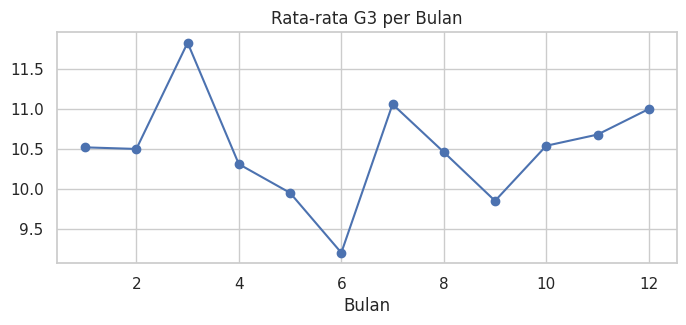

In [37]:
agg["G3"].plot(marker="o", figsize=(8, 3), title="Rata-rata G3 per Bulan"); plt.show()

**4f. Smoothing: moving average (window = 5) pada `G3`**


In [38]:
tmp = dfc.sort_values("ID_Siswa").reset_index(drop=True)
tmp["G3_MA"] = tmp.G3.rolling(window=5, min_periods=1).mean()
tmp[["ID_Siswa", "G3", "G3_MA"]].head(10)

,ID_Siswa,G3,G3_MA
0,S001,6,6.000000
1,S002,6,6.000000
2,S003,10,7.333333
3,S004,15,9.250000
4,S005,10,9.400000
5,S006,15,11.200000
6,S007,11,12.200000
7,S008,6,11.400000
8,S009,19,12.200000
9,S010,15,13.200000


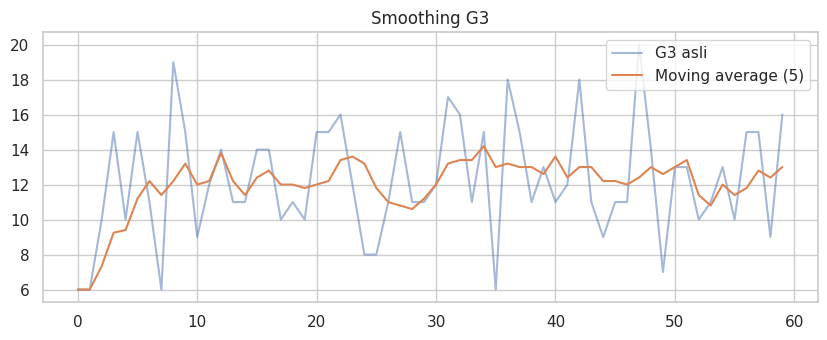

In [39]:
plt.figure(figsize=(10, 3.5)); plt.plot(tmp.G3[:60], alpha=.5, label="G3 asli"); plt.plot(tmp.G3_MA[:60], label="Moving average (5)")
plt.legend(); plt.title("Smoothing G3"); plt.show()

**Kegunaan:** moving average meredam fluktuasi acak sehingga tren lebih mudah dilihat dan noise berkurang.


---
## TAHAP 5 – Reduksi Data
**INPUT:** `dfc` dengan variabel numerik
**PROSES:** korelasi - variabel redundan - standardisasi - PCA - pilih jumlah komponen - interpretasi.
**OUTPUT:** variabel redundan dibuang, data tereduksi (komponen utama), tabel sebelum–sesudah.



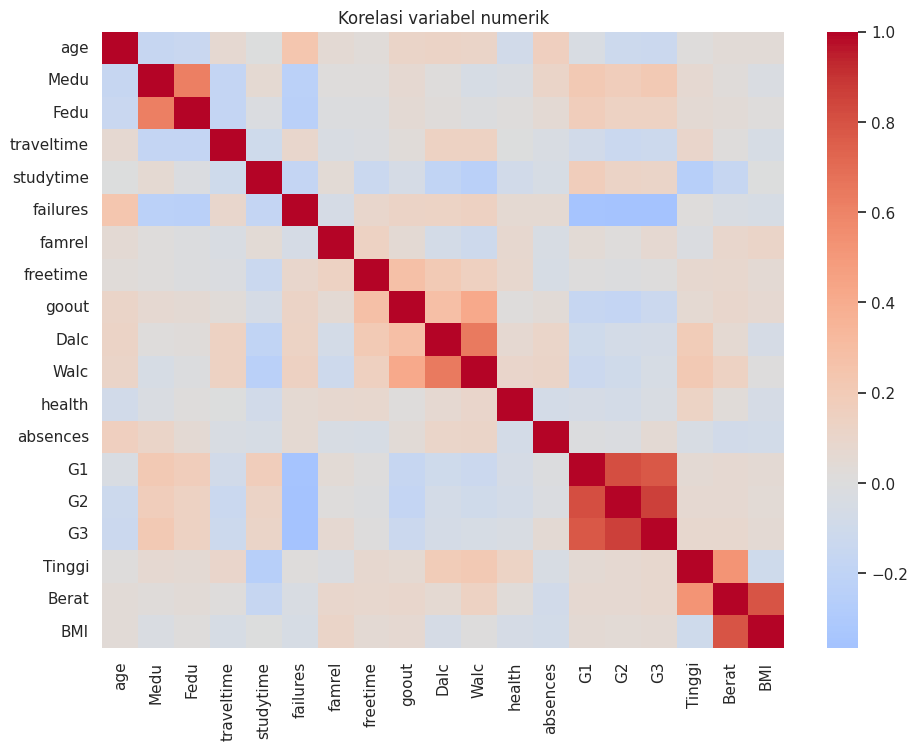

Pasangan variabel |r| >= 0.6:


,,0
G2,G3,0.856
G1,G2,0.814
Berat,BMI,0.788
G1,G3,0.780
Dalc,Walc,0.638
Medu,Fedu,0.618


In [40]:
num_feat = ["age","Medu","Fedu","traveltime","studytime","failures","famrel","freetime","goout","Dalc","Walc",
            "health","absences","G1","G2","G3","Tinggi","Berat","BMI"]
corr = dfc[num_feat].corr()
plt.figure(figsize=(11, 8)); sns.heatmap(corr, cmap="coolwarm", center=0, annot=False); plt.title("Korelasi variabel numerik"); plt.show()
pairs = corr.where(np.triu(np.ones(corr.shape), 1).astype(bool)).stack()
pairs = pairs[pairs.abs() >= 0.6].sort_values(key=abs, ascending=False).round(3)
print("Pasangan variabel |r| >= 0.6:"); pairs

**Variabel redundan / tidak berguna yang dibuang:**
- `ID_Siswa` – hanya identitas, tidak punya nilai prediksi.
- `G1` – berkorelasi sangat tinggi dengan `G2` dan `G3` (informasi tumpang tindih).
- `Status_Kesehatan` – turunan dari `health` (informasi sama, hanya dikelompokkan).
- `Kategori_BMI`, `Bulan` tidak ikut PCA (kategorik turunan / penanda waktu pengambilan data).

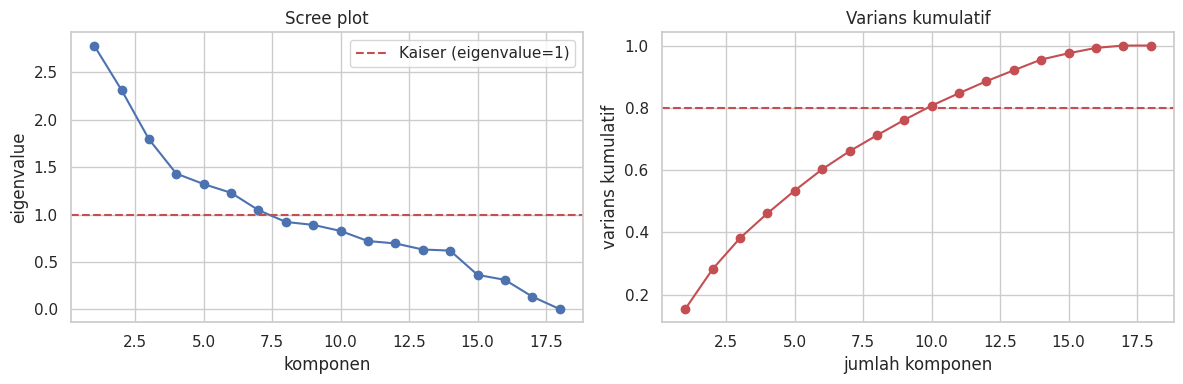

Variabel awal: 18 | komponen untuk >= 80% varians: 10 | komponen eigenvalue > 1 (Kaiser): 7


In [41]:
from sklearn.decomposition import PCA
pca_cols = [c for c in num_feat if c != "G1"]
X = StandardScaler().fit_transform(dfc[pca_cols])
X = pd.DataFrame(X, columns=pca_cols)

pca_full = PCA().fit(X)
ev = pca_full.explained_variance_ratio_
cum = ev.cumsum()
k80 = int(np.argmax(cum >= 0.80) + 1)
kaiser = int((pca_full.explained_variance_ > 1).sum())

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(range(1, len(ev) + 1), pca_full.explained_variance_, "-ob"); ax[0].axhline(1, color="r", ls="--", label="Kaiser (eigenvalue=1)")
ax[0].set_xlabel("komponen"); ax[0].set_ylabel("eigenvalue"); ax[0].set_title("Scree plot"); ax[0].legend()
ax[1].plot(range(1, len(ev) + 1), cum, "-or"); ax[1].axhline(.8, color="r", ls="--"); ax[1].set_xlabel("jumlah komponen"); ax[1].set_ylabel("varians kumulatif"); ax[1].set_title("Varians kumulatif")
plt.tight_layout(); plt.show()
print(f"Variabel awal: {len(pca_cols)} | komponen untuk >= 80% varians: {k80} | komponen eigenvalue > 1 (Kaiser): {kaiser}")

In [42]:
pca = PCA(n_components=k80).fit(X)
loading = pd.DataFrame(pca.components_.T, index=pca_cols, columns=[f"PC{i+1}" for i in range(k80)])
for pc in ["PC1", "PC2", "PC3"]:
    top = loading[pc].reindex(loading[pc].abs().sort_values(ascending=False).index).head(5).round(3)
    print(f"{pc} (varians {pca.explained_variance_ratio_[int(pc[2:])-1]*100:.1f}%):", top.to_dict())
df_pca = pd.DataFrame(pca.transform(X), columns=[f"PC{i+1}" for i in range(k80)])
df_pca["Test_Result"] = dfc.Test_Result.values
df_pca.head()

PC1 (varians 15.4%): {'G2': 0.398, 'G3': 0.386, 'failures': -0.36, 'Walc': -0.337, 'Dalc': -0.307}
PC2 (varians 12.8%): {'Berat': 0.454, 'Tinggi': 0.36, 'Walc': 0.309, 'Dalc': 0.278, 'G3': 0.278}
PC3 (varians 9.9%): {'BMI': 0.535, 'Berat': 0.491, 'Medu': -0.327, 'Fedu': -0.3, 'Dalc': -0.289}


,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,Test_Result
0,-0.900674,2.444431,-1.626180,-0.332907,-0.639755,-0.372958,-0.079063,-0.218265,-0.311449,0.976117,Pass
1,-1.566449,-0.644402,-0.784641,1.024910,-1.032188,-0.307777,1.567043,-0.071924,0.632066,1.372484,Fail
2,0.454993,0.846507,-1.542195,1.405371,0.483289,-0.374765,-1.842283,-1.725497,-0.235190,-0.625209,Pass
3,0.358737,2.814762,-0.220022,0.948622,-1.105739,0.965697,-0.281286,-0.251851,0.849976,-0.630243,Pass
4,-1.425466,-1.392745,2.019667,2.383744,0.638282,0.801969,0.784733,-0.118248,1.079144,0.734401,Fail


**Interpretasi PCA (berdasarkan loading di atas):** PC1 menggambarkan *prestasi akademik* (G2 dan G3 positif, berlawanan dengan `failures` dan konsumsi alkohol `Walc`/`Dalc`); PC2 menggambarkan *ukuran fisik* (`Berat` dan `Tinggi`); PC3 menggambarkan *komposisi tubuh* (`BMI`, `Berat`) yang berlawanan dengan pendidikan orang tua (`Medu`/`Fedu`). Jumlah komponen dipilih dengan syarat varians kumulatif ≥ 80% (10 komponen dari 18 variabel), dan sebagai pembanding kriteria Kaiser (eigenvalue > 1) memberi 7 komponen. Karena korelasi antar variabel (selain G1-G3) tergolong rendah, reduksi dimensinya tidak terlalu besar.


**5b. Distribusi kelas Test_Result**


In [43]:
print(dfc.Test_Result.value_counts()); print((dfc.Test_Result.value_counts(normalize=True) * 100).round(1))

Test_Result
Pass    265
Fail    130
Name: count, dtype: int64
Test_Result
Pass    67.1
Fail    32.9
Name: proportion, dtype: float64


**5c. Perbandingan sebelum dan sesudah preprocessing**

In [44]:
sebelum = {"baris": len(df_raw), "kolom": df_raw.shape[1], "missing (NaN)": int(df_raw.isna().sum().sum()),
           "missing tersamar (teks)": int(ph.sum()), "duplikat persis": int(df_raw.duplicated().sum()),
           "kolom numerik bertipe teks": int((tipe_salah.jumlah_non_angka > 0).sum())}
sesudah = {"baris": len(dfc), "kolom": dfc.shape[1], "missing (NaN)": int(dfc.isna().sum().sum()),
           "missing tersamar (teks)": 0, "duplikat persis": int(dfc.duplicated().sum()), "kolom numerik bertipe teks": 0}
pd.DataFrame({"Sebelum": sebelum, "Sesudah": sesudah})

,Sebelum,Sesudah
baris,412,395
kolom,33,35
missing (NaN),416,0
missing tersamar (teks),35,0
duplikat persis,12,0
kolom numerik bertipe teks,4,0


In [45]:
# simpan hasil
dfc.drop(columns=["Kategori_BMI"]).to_csv("dataset_student_bersih.csv", index=False)
dfe.to_csv("dataset_student_encoded.csv", index=False)
print("Tersimpan: dataset_student_bersih.csv, dataset_student_encoded.csv")

Tersimpan: dataset_student_bersih.csv, dataset_student_encoded.csv


Jadi data mentah yang mengandung typo, spasi/huruf tidak seragam, tipe data dan satuan salah, missing value (nyata dan tersamar), outlier, duplikat, serta inkonsistensi antar variabel telah dibersihkan, ditransformasi (normalisasi, encoding, diskretisasi, BMI, agregasi, smoothing), dan direduksi (pembuangan variabel redundan dan PCA) sehingga siap dipakai untuk klasifikasi `Test_Result`.